<a href="https://colab.research.google.com/github/nellimarlabhanukeerthi-spec/Capstone_project_playstore/blob/main/Face_Expression_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ultralytics


from ultralytics import YOLO

model = YOLO("yolo26n-cls.pt")

# Ultralytics automatically downloads MNIST160
results = model.train(
    data="mnist160",
    epochs=2,
    imgsz=64
)

import os

print("Current folder contents:")
print(os.listdir("/content"))


Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=mnist160, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=64, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True,

In [ ]:

import zipfile
import os

for name in os.listdir("/content"):
    if name.lower().endswith(".zip"):
        path = os.path.join("/content", name)
        print("\nZIP:", name)

        with zipfile.ZipFile(path, "r") as z:
            print("First 15 items:")
            print(z.namelist()[:15])


In [ ]:

import os
import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass.getpass(
    "Paste your NEW Kaggle API token here: "
)

print("Kaggle token entered securely.")


Paste your NEW Kaggle API token here: ··········
Kaggle token entered securely.


In [ ]:

!pip install -q kaggle

!kaggle datasets download \
    -d msambare/fer2013 \
    -p /content/fer_data


Dataset URL: https://www.kaggle.com/datasets/msambare/fer2013
License(s): DbCL-1.0
100% 60.3M/60.3M [00:00<00:00, 153MB/s]



In [ ]:

import os
import zipfile
from pathlib import Path

download_dir = Path("/content/fer_data")
zip_path = download_dir / "fer2013.zip"
extract_dir = download_dir / "extracted"

extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extraction successful!")
print("Files and folders found:")
print(os.listdir(extract_dir))


Extraction successful!
Files and folders found:
['train', 'test']


In [ ]:

from pathlib import Path

for path in Path("/content/fer_data/extracted").rglob("*"):
    if path.is_dir() and path.name.lower() in ["train", "test"]:
        print("Found dataset folder:", path)
        print("Classes:", [
            p.name for p in path.iterdir() if p.is_dir()
        ])


Found dataset folder: /content/fer_data/extracted/train
Classes: ['disgust', 'angry', 'sad', 'happy', 'surprise', 'fear', 'neutral']
Found dataset folder: /content/fer_data/extracted/test
Classes: ['disgust', 'angry', 'sad', 'happy', 'surprise', 'fear', 'neutral']


In [ ]:

import random
import shutil
from pathlib import Path

# Original dataset folders
source_train = Path("/content/fer_data/extracted/train")
source_test = Path("/content/fer_data/extracted/test")

# New dataset folder for YOLO
output_dir = Path("/content/face_expression_dataset")

# Supported image formats
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Reproducible random split
random.seed(42)

# Check the source folders
assert source_train.exists(), "Training folder not found"
assert source_test.exists(), "Test folder not found"

classes = sorted(
    folder.name for folder in source_train.iterdir()
    if folder.is_dir()
)

print("Classes:", classes)

# Remove an old output folder if this cell is run again
if output_dir.exists():
    shutil.rmtree(output_dir)

# Create train, val and test folders
for split in ["train", "val", "test"]:
    for cls in classes:
        (output_dir / split / cls).mkdir(
            parents=True, exist_ok=True
        )

# Split original training images 80/20
for cls in classes:
    images = [
        p for p in (source_train / cls).rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    random.shuffle(images)
    cut = int(len(images) * 0.8)

    for img in images[:cut]:
        shutil.copy2(img, output_dir / "train" / cls / img.name)

    for img in images[cut:]:
        shutil.copy2(img, output_dir / "val" / cls / img.name)

# Copy original test images unchanged
for cls in classes:
    for img in (source_test / cls).rglob("*"):
        if img.is_file() and img.suffix.lower() in image_extensions:
            shutil.copy2(img, output_dir / "test" / cls / img.name)

print("\nDataset split completed!")
print("Dataset location:", output_dir)


Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

Dataset split completed!
Dataset location: /content/face_expression_dataset


In [ ]:

for split in ["train", "val", "test"]:
    total = 0
    print(f"\n{split.upper()}")

    for cls in classes:
        folder = output_dir / split / cls
        count = sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in image_extensions
        )
        total += count
        print(f"  {cls}: {count}")

    print("Total images:", total)



TRAIN
  angry: 3196
  disgust: 348
  fear: 3277
  happy: 5772
  neutral: 3972
  sad: 3864
  surprise: 2536
Total images: 22965

VAL
  angry: 799
  disgust: 88
  fear: 820
  happy: 1443
  neutral: 993
  sad: 966
  surprise: 635
Total images: 5744

TEST
  angry: 958
  disgust: 111
  fear: 1024
  happy: 1774
  neutral: 1233
  sad: 1247
  surprise: 831
Total images: 7178


In [19]:
from ultralytics import YOLO

# Load a pretrained YOLO image-classification model
model = YOLO("yolo26n-cls.pt")

# Train on your facial-expression dataset
results = model.train(
    data="/content/face_expression_dataset",
    epochs=10,
    imgsz=48,
    batch=16,
    seed=42,
    project="/content/face_expression_project",
    name="fer2013"
)

print("Face-expression model training completed!")

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/face_expression_dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=48, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fer2013, nbs=64, nms=None, opset=None, optimize=False, optimizer

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
YOLO26n-cls summary (fused): 47 layers, 1,534,991 parameters, 0 gradients, 3.2 GFLOPs
train: /content/face_expression_dataset/train... found 22965 images in 7 classes ✅ 
val: /content/face_expression_dataset/val... found 5744 images in 7 classes ✅ 
test: /content/face_expression_dataset/test... found 7178 images in 7 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 140.8±70.1 MB/s, size: 1.6 KB)
test: Scanning /content/face_expression_dataset/test... 7178 images, 0 corrupt: 100% ━━━━━━━━━━━━ 7178/7178 1.9Git/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 449/449 42.7it/s 10.5s
                   all      0.607      0.985
Speed: 0.0ms preprocess, 1.0ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val-5

 FINAL TEST RESULTS
Top-1 accuracy: 60.66 %
Top-5 accuracy: 98.45 %


Saving angry images.jpg to angry images.jpg

image 1/1 /content/angry images.jpg: 64x64 neutral 0.35, happy 0.32, sad 0.15, fear 0.08, surprise 0.06, 3.8ms
Speed: 2.8ms preprocess, 3.8ms inference, 0.0ms postprocess per image at shape (1, 3, 64, 64)
Predicted expression: neutral
Model confidence: 35.22 %


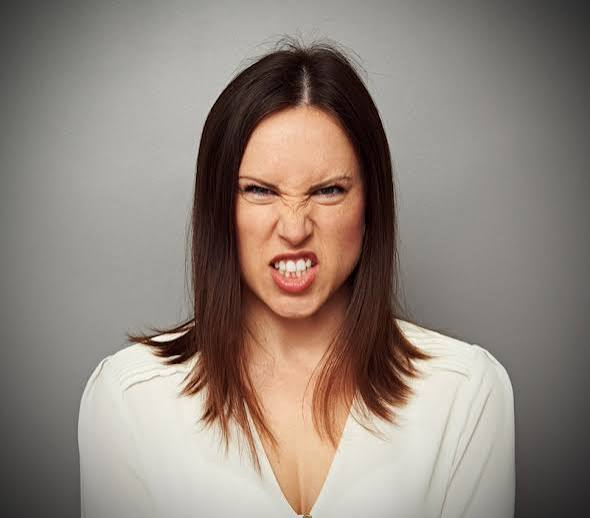

In [24]:
from ultralytics import YOLO

model_path=(
    "/content/face_expression_project/fer2013/weights/best.pt"
)
data_path = "/content/face_expression_dataset"

model=YOLO(model_path)
metrics =model.val(
    data=data_path,
    split="test",
    imgsz=64
)
print("\n FINAL TEST RESULTS")
print("Top-1 accuracy:",round(float(metrics.top1)*100,2),"%")
print("Top-5 accuracy:",round(float(metrics.top5)*100,2),"%")

from google.colab import files
from IPython.display import display
from PIL import Image

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

results = model.predict(
    source=image_path,
    imgsz=64
)

result = results[0]
predicted_class = result.names[result.probs.top1]
confidence = float(result.probs.top1conf) * 100

print("Predicted expression:", predicted_class)
print("Model confidence:", round(confidence, 2), "%")

display(Image.open(image_path))

Saving neutral images.jpg to neutral images (2).jpg

image 1/1 /content/neutral images (2).jpg: 64x64 happy 0.74, fear 0.07, angry 0.06, surprise 0.06, neutral 0.03, 4.1ms
Speed: 2.1ms preprocess, 4.1ms inference, 0.0ms postprocess per image at shape (1, 3, 64, 64)
Predicted expression: happy
Model confidence: 74.17 %


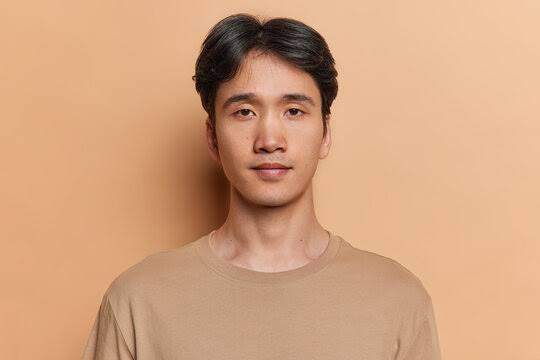

In [27]:
from google.colab import files
from IPython.display import display
from PIL import Image

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

results = model.predict(
    source=image_path,
    imgsz=64
)

result = results[0]
predicted_class = result.names[result.probs.top1]
confidence = float(result.probs.top1conf) * 100

print("Predicted expression:", predicted_class)
print("Model confidence:", round(confidence, 2), "%")

display(Image.open(image_path))

Selected training image: Training_10116721.jpg (True class: happy)
WARNING ⚠️ imgsz=[48] must be multiple of max stride 32, updating to [64]
Model Prediction: happy (90.21% confidence)


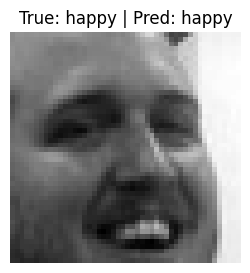

In [28]:
import random
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
from ultralytics import YOLO

def search_and_test_train_data(emotion_class, image_index=0):
    """
    Searches for an image in the trained dataset by emotion class and index,
    runs our trained YOLO model on it, and displays the prediction.
    """
    train_dir = Path("/content/face_expression_dataset/train")
    class_dir = train_dir / emotion_class.lower()

    if not class_dir.exists():
        available_classes = [p.name for p in train_dir.iterdir() if p.is_dir()]
        print(f"Class '{emotion_class}' not found. Available classes: {available_classes}")
        return

    # Get all images in the folder
    images = sorted(list(class_dir.glob("*")))
    if not images:
        print(f"No images found in {class_dir}")
        return

    if image_index >= len(images):
        print(f"Index {image_index} is out of range. There are {len(images)} images in this class.")
        image_index = len(images) - 1
        print(f"Using the last image (index {image_index}) instead.")

    selected_image_path = images[image_index]
    print(f"Selected training image: {selected_image_path.name} (True class: {emotion_class})")

    # Load model and predict
    model_path = "/content/face_expression_project/fer2013/weights/best.pt"
    model = YOLO(model_path)
    results = model.predict(source=str(selected_image_path), imgsz=48, verbose=False)

    result = results[0]
    predicted_class = result.names[result.probs.top1]
    confidence = float(result.probs.top1conf) * 100

    print(f"Model Prediction: {predicted_class} ({confidence:.2f}% confidence)")

    # Display image
    img = Image.open(selected_image_path)
    plt.figure(figsize=(3, 3))
    plt.imshow(img, cmap='gray' if img.mode == 'L' else None)
    plt.title(f"True: {emotion_class} | Pred: {predicted_class}")
    plt.axis('off')
    plt.show()

# Example Search: Let's test the 5th image (index 4) from the 'happy' training folder
search_and_test_train_data(emotion_class="happy", image_index=4)

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
YOLO26n-cls summary (fused): 47 layers, 1,534,991 parameters, 0 gradients, 3.2 GFLOPs
train: /content/face_expression_dataset/train... found 22965 images in 7 classes ✅ 
val: /content/face_expression_dataset/val... found 5744 images in 7 classes ✅ 
test: /content/face_expression_dataset/test... found 7178 images in 7 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 113.2±68.4 MB/s, size: 1.6 KB)
test: Scanning /content/face_expression_dataset/test... 7178 images, 0 corrupt: 100% ━━━━━━━━━━━━ 7178/7178 1.9Git/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 449/449 45.9it/s 9.8s
                   all      0.607      0.985
Speed: 0.0ms preprocess, 0.9ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val-8


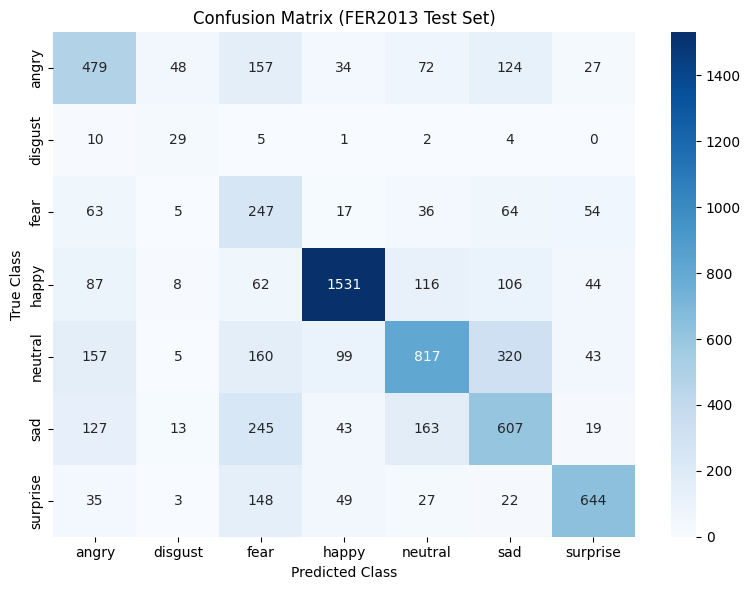

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics import YOLO
import numpy as np

# Load our best trained model
model_path = "/content/face_expression_project/fer2013/weights/best.pt"
model = YOLO(model_path)

# Validate on the test split to compute the confusion matrix
metrics = model.val(data="/content/face_expression_dataset", split="test", imgsz=64, verbose=False)

# Extract the confusion matrix and cast to integer
cm = metrics.confusion_matrix.matrix.astype(int)

# Get class names directly from the model
classes = [model.names[i] for i in range(len(model.names))]

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix (FER2013 Test Set)")
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.tight_layout()
plt.show()

In [32]:
import pandas as pd

# We already have 'cm' and 'classes' in the kernel state
precisions = []
recalls = []

for i, cls_name in enumerate(classes):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    precisions.append(precision)
    recalls.append(recall)

# Create a neat summary DataFrame
metrics_df = pd.DataFrame({
    'Class': classes,
    'Precision': precisions,
    'Recall': recalls
})

# Format as percentages for easier reading
metrics_df['Precision'] = metrics_df['Precision'].map(lambda x: f"{x:.2%}")
metrics_df['Recall'] = metrics_df['Recall'].map(lambda x: f"{x:.2%}")

display(metrics_df)

,Class,Precision,Recall
0,angry,50.00%,50.90%
1,disgust,26.13%,56.86%
2,fear,24.12%,50.82%
3,happy,86.30%,78.35%
4,neutral,66.26%,51.03%
5,sad,48.68%,49.88%
6,surprise,77.50%,69.40%


In [33]:
%%writefile app.py
import streamlit as st
from PIL import Image
from ultralytics import YOLO
import numpy as np

st.set_page_config(page_title="Facial Expression Recognition", layout="centered")

st.title("☱ Facial Expression Classifier")
st.write("Upload a face image to classify its emotion using our trained YOLO model!")

# Load the trained model
@st.cache_resource
def load_model():
    model_path = "/content/face_expression_project/fer2013/weights/best.pt"
    return YOLO(model_path)

try:
    model = load_model()
    st.success("Model loaded successfully!")
except Exception as e:
    st.error(f"Failed to load model. Error: {e}")

uploaded_file = st.file_uploader("Choose an image...", type=["jpg", "jpeg", "png", "webp", "bmp"])

if uploaded_file is not None:
    # Display uploaded image
    image = Image.open(uploaded_file)
    st.image(image, caption="Uploaded Image", use_container_width=True)

    st.write("Classifying...")

    # Run prediction
    # We convert image to RGB just in case it is grayscale or RGBA
    results = model.predict(source=image.convert("RGB"), imgsz=64, verbose=False)
    result = results[0]

    # Get predictions ordered by probability
    probs = result.probs
    top1_idx = probs.top1
    predicted_class = result.names[top1_idx]
    confidence = float(probs.top1conf) * 100

    st.metric(label="Predicted Emotion", value=predicted_class.upper(), delta=f"{confidence:.2f}% Confidence")

    # Show probability bar chart for all classes
    st.write("### Class Probabilities:")
    chart_data = {}
    for idx, name in result.names.items():
        chart_data[name] = float(probs.data[idx])

    st.bar_chart(chart_data)

Writing app.py


In [34]:
# Install necessary tools for running and tunneling the Streamlit app
!pip install -q streamlit
!npm install -g localtunnel

# Print the public IP address (which localtunnel will ask for as a password protection tunnel password)
import urllib
print("Your Tunnel Password (IP Address):", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip())

# Run Streamlit in background and expose it using localtunnel
get_ipython().system_raw("streamlit run app.py & npx localtunnel --port 8501 &")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 41.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 55.7 MB/s eta 0:00:00
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴
added 22 packages in 2s
⠴
⠴3 packages are looking for funding
⠴  run `npm fund` for details
⠴Your Tunnel Password (IP Address): 34.106.214.134


In [36]:
import time
import os

# Terminate any existing localtunnel processes to prevent port conflicts
!pkill -f localtunnel

# Start localtunnel in the background and write its output to a log file
print("Starting localtunnel...")
get_ipython().system_raw("npx localtunnel --port 8501 > localtunnel.log 2>&1 &")

# Give the tunnel 5 seconds to establish connection and retrieve the URL
time.sleep(5)

# Read and display the generated public URL
if os.path.exists("localtunnel.log"):
    with open("localtunnel.log", "r") as f:
        log_content = f.read()
    print("--- Localtunnel Output ---")
    print(log_content)
else:
    print("Log file not found. Please try running this cell again in a few seconds.")

Starting localtunnel...
--- Localtunnel Output ---
your url is: https://neat-flowers-battle.loca.lt

